# Dữ liệu và tiền xử lý GTSRB

**Mục tiêu:** đọc ảnh và nhãn, kiểm tra dữ liệu, chia train/validation theo track,
giữ test chính thức, thống kê lớp và minh họa resize/chuyển màu.

## 1. Thư viện và cấu hình
Nếu thiếu thư viện, bỏ dấu `#` ở dòng cài đặt bên dưới rồi chạy một lần.
Chỉ thay `PROJECT` nếu dữ liệu nằm ở nơi khác. Đường dẫn trong các CSV sẽ tương đối với `DATA`.

In [1]:
# %pip install numpy pandas opencv-python matplotlib

from pathlib import Path
import hashlib
import json
import shutil
import urllib.request
import zipfile

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

PROJECT = Path.cwd()
if PROJECT.name == "code":
    PROJECT = PROJECT.parent

DATA = PROJECT / "data/raw"
SPLITS = PROJECT / "splits"
OUTPUT = PROJECT / "results/notebook"
SAMPLES = PROJECT / "samples"
SEED = 42
VAL_RATIO = 0.2
SIZE = (64, 64)  # (chiều rộng, chiều cao)

for folder in [DATA, SPLITS, OUTPUT, SAMPLES]:
    folder.mkdir(parents=True, exist_ok=True)

print("Thư mục dự án:", PROJECT.resolve())

def table_html(html):
    import re
    html = re.sub(r"<style.*?</style>", "", html, flags=re.DOTALL)
    header = "color:#172b4d !important;background:#e8eef5 !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    body = "color:#172b4d !important;background:#ffffff !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    html = re.sub(r"<th(?=[ >])", '<th style="' + header + '"', html)
    html = re.sub(r"<td(?=[ >])", '<td style="' + body + '"', html)
    html = html.replace("<table ", '<table style="border-collapse:collapse;font-family:Arial,sans-serif;font-size:13px;" ')
    return '<div style="background:#fff;color:#172b4d;padding:10px;max-width:100%;overflow-x:auto;">' + html + '</div>'


def show_table(table):
    # Series (một cột) được chuyển thành bảng trước khi hiển thị.
    if isinstance(table, pd.Series):
        table = table.to_frame(name="Giá trị")
    display(HTML(table_html(table.to_html(border=0))))


Thư mục dự án: C:\Users\Dat\Documents\Study\Projects\XLA_N7_CT


## 2. Tải dữ liệu (chỉ khi chưa có)

Giữ `DOWNLOAD = False` nếu dữ liệu đã được tải và giải nén.
Khi chạy ở máy mới, đổi thành `True` (cần mạng, vài GB trống).

Nguồn: [GTSRB](https://benchmark.ini.rub.de/gtsrb_dataset.html), mirror ERDA.
Dùng **Final Training 39.209 ảnh**, không dùng `Training_fixed` giai đoạn cũ 26.640 ảnh.
Test gồm gói ảnh và gói nhãn GT riêng.
SHA-256 của ba ZIP giúp kiểm tra file tải có đầy đủ và đúng bản hay không.
Các hash đã được xác nhận ở lần chuẩn bị dữ liệu của dự án.

In [2]:
DOWNLOAD = False
BASE_URL = "https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/"
archives = {
    "GTSRB_Final_Training_Images.zip": "d32ac4b5fa9a1cbd1994768413902e8193599d9434cf0a8eb9cfd00a6d3a290c",
    "GTSRB_Final_Test_Images.zip": "48ba6fab7e877eb64eaf8de99035b0aaecfbc279bee23e35deca4ac1d0a837fa",
    "GTSRB_Final_Test_GT.zip": "f94e5a7614d75845c74c04ddb26b8796b9e483f43541dd95dd5b726504e16d6d",
}

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

if DOWNLOAD:
    archive_dir = DATA / "archives"
    archive_dir.mkdir(exist_ok=True)
    for name, expected_hash in archives.items():
        path = archive_dir / name
        if not path.exists() or sha256_file(path) != expected_hash:
            print("Đang tải:", name, flush=True)
            temporary = path.with_suffix(".zip.part")
            urllib.request.urlretrieve(BASE_URL + name, temporary)
            assert sha256_file(temporary) == expected_hash, "File tải sai hoặc chưa đầy đủ"
            temporary.replace(path)
        print("Checksum đúng, giải nén:", name, flush=True)
        with zipfile.ZipFile(path) as archive:
            for member in archive.namelist():
                assert (DATA / member).resolve().is_relative_to(DATA.resolve())
            archive.extractall(DATA)
else:
    print("Dùng dữ liệu sẵn có; không tải lại.")

Dùng dữ liệu sẵn có; không tải lại.


## 3. Kiểm tra cấu trúc và đọc nhãn

Cấu trúc gốc cần có:
```text
data/raw/GTSRB/Final_Training/Images/00000/GT-00000.csv
data/raw/GTSRB/Final_Training/Images/00000/00000_00000.ppm
... (43 thư mục lớp)
data/raw/GTSRB/Final_Test/Images/00000.ppm
data/raw/GT-final_test.csv
```
Nhãn CSV được phân cách bằng `;`. Không đoán nhãn test từ tên ảnh.
Tên train `TTTTT_FFFFF.ppm` chứa mã track và mã khung hình.
Số track lặp lại giữa các lớp nên khóa nhóm phải gồm **cả lớp và track**.
Bản dữ liệu mất tên gốc/track phải khôi phục trước khi chia tập.

In [3]:
TRAIN_DIR = DATA / "GTSRB/Final_Training/Images"
TEST_DIR = DATA / "GTSRB/Final_Test/Images"
TEST_CSV = DATA / "GT-final_test.csv"

assert TRAIN_DIR.is_dir(), "Chưa có Final Training: kiểm tra DATA hoặc bật DOWNLOAD"
assert TEST_DIR.is_dir() and TEST_CSV.is_file(), "Thiếu ảnh test hoặc nhãn test"
print("Số thư mục lớp:", len(list(TRAIN_DIR.glob("[0-9][0-9][0-9][0-9][0-9]"))))

def read_annotations(csv_path, image_dir, source):
    table = pd.read_csv(csv_path, sep=";")
    assert table["Filename"].is_unique, f"Trùng tên trong {csv_path}"
    assert table["ClassId"].between(0, 42).all(), "Nhãn ngoài 0–42"
    assert (table["ClassId"] % 1 == 0).all(), "Nhãn phải là số nguyên"
    assert set(table["Filename"]) == {p.name for p in image_dir.glob("*.ppm")}, "Ảnh và CSV không khớp"

    table = table.rename(columns={"ClassId": "class_id"})
    table["path"] = [(image_dir / name).relative_to(DATA).as_posix() for name in table["Filename"]]
    table["source"] = source
    table["track_id"] = ""  # Tên test phẳng không cung cấp track
    if source == "official_train":
        assert table["Filename"].str.fullmatch(r"\d{5}_\d{5}\.ppm").all(), "Mất tên file chứa track"
        assert (table["class_id"] == int(image_dir.name)).all(), "Nhãn khác thư mục lớp"
        table["track_id"] = image_dir.name + ":" + table["Filename"].str[:5]

    columns = ["path", "class_id", "track_id", "source",
               "Width", "Height", "Roi.X1", "Roi.Y1", "Roi.X2", "Roi.Y2"]
    return table[columns]

train_tables = []
for label in range(43):
    folder = TRAIN_DIR / f"{label:05d}"
    train_tables.append(read_annotations(folder / f"GT-{label:05d}.csv", folder, "official_train"))

official_train = pd.concat(train_tables, ignore_index=True)
official_test = read_annotations(TEST_CSV, TEST_DIR, "official_test")
data = pd.concat([official_train, official_test], ignore_index=True)

assert len(official_train) == 39209 and len(official_test) == 12630, "Sai phiên bản hoặc thiếu dữ liệu"
assert data["path"].is_unique, "Trùng đường dẫn ảnh"
assert set(official_train.class_id) == set(official_test.class_id) == set(range(43))
print("Train chính thức:", len(official_train), "| Test chính thức:", len(official_test))
show_table(official_train.head())

Số thư mục lớp: 43


Train chính thức: 39209 | Test chính thức: 12630


,path,class_id,track_id,source,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2
0,GTSRB/Final_Training/Images/00000/00000_00000.ppm,0,00000:00000,official_train,29,30,5,6,24,25
1,GTSRB/Final_Training/Images/00000/00000_00001.ppm,0,00000:00000,official_train,30,30,5,5,25,25
2,GTSRB/Final_Training/Images/00000/00000_00002.ppm,0,00000:00000,official_train,30,30,5,5,25,25
3,GTSRB/Final_Training/Images/00000/00000_00003.ppm,0,00000:00000,official_train,31,31,5,5,26,26
4,GTSRB/Final_Training/Images/00000/00000_00004.ppm,0,00000:00000,official_train,30,32,5,6,25,26


## 4. Kiểm tra ảnh có đọc được không

Giải mã **toàn bộ ảnh** và đối chiếu kích thước với CSV; bước này có thể mất vài phút.
Hàm dùng `read_bytes` để đọc được đường dẫn tiếng Việt trên Windows.
Không âm thầm bỏ ảnh hỏng. Kích thước metadata lệch được ghi cảnh báo;
kích thước ảnh giải mã là căn cứ để resize.

In [4]:
def read_bgr(path):
    payload = Path(path).read_bytes()
    if not payload:
        raise ValueError("File ảnh rỗng")
    image = cv2.imdecode(np.frombuffer(payload, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Không giải mã được ảnh")
    return image

issues = []
dimensions = []
for i, row in enumerate(data.to_dict("records"), start=1):
    try:
        image = read_bgr(DATA / row["path"])
        height, width = image.shape[:2]
        dimensions.append({"path": row["path"], "width": width, "height": height})
        if width != row["Width"] or height != row["Height"]:
            issues.append({"path": row["path"], "severity": "warning", "issue": "Kích thước khác CSV"})
    except (OSError, ValueError, cv2.error) as error:
        issues.append({"path": row["path"], "severity": "error", "issue": str(error)})
    if i % 10000 == 0:
        print(f"Đã kiểm tra {i}/{len(data)} ảnh", flush=True)

issues_df = pd.DataFrame(issues, columns=["path", "severity", "issue"])
dimensions_df = pd.DataFrame(dimensions)
issues_df.to_csv(OUTPUT / "data_issues.csv", index=False)
dimensions_df.to_csv(OUTPUT / "image_dimensions.csv", index=False)
print("Lỗi đọc ảnh:", (issues_df.severity == "error").sum())
print("Cảnh báo kích thước:", (issues_df.severity == "warning").sum())
assert not (issues_df.severity == "error").any(), "Sửa dữ liệu lỗi trước khi chia tập"
show_table(dimensions_df[["width", "height"]].agg(["min", "max"]))

Đã kiểm tra 10000/51839 ảnh


Đã kiểm tra 20000/51839 ảnh


Đã kiểm tra 30000/51839 ảnh


Đã kiểm tra 40000/51839 ảnh


Đã kiểm tra 50000/51839 ảnh


Lỗi đọc ảnh: 0
Cảnh báo kích thước: 0


,width,height
min,25,25
max,266,232


## 5. Chia train/validation theo track

Trong từng lớp, chọn khoảng 20% **số track** vào validation với seed 42.
Mỗi track được đưa nguyên vẹn vào một tập. Vì làm tròn nguyên track,
tỉ lệ **ảnh** validation có thể hơi khác 20%. Không cân bằng lại hay chọn lại test.

In [5]:
assert 0 < VAL_RATIO < 1
rng = np.random.default_rng(SEED)
validation_tracks = []

for label, group in official_train.groupby("class_id", sort=True):
    tracks = sorted(group["track_id"].unique())
    assert len(tracks) >= 2, f"Lớp {label} không đủ track để chia"
    number = int(np.floor(len(tracks) * VAL_RATIO + 0.5))
    number = max(1, min(number, len(tracks) - 1))
    validation_tracks.extend(rng.permutation(tracks)[:number])

is_validation = official_train["track_id"].isin(validation_tracks)
parts = {
    "train": official_train[~is_validation].copy(),
    "validation": official_train[is_validation].copy(),
    "test": official_test.copy(),
}

assert not (set(parts["train"].track_id) & set(parts["validation"].track_id)), "Trùng track!"
assert sum(len(part) for part in parts.values()) == len(data)
assert len(set().union(*(set(part.path) for part in parts.values()))) == len(data)
for name, part in parts.items():
    assert set(part.class_id) == set(range(43)), f"Thiếu lớp trong {name}"
    print(name, ":", len(part), "ảnh")

train : 31380 ảnh
validation : 7829 ảnh
test : 12630 ảnh


## 6. Lưu danh sách cố định

Chỉ tạo CSV nếu chưa có. Nếu đã có, kiểm tra xem kết quả chia có giống danh sách đã chốt không
và **dùng lại file cũ**, không ghi đè. Nếu khác, notebook dừng để tránh đổi tập giữa thí nghiệm.
Muốn thử seed/tỉ lệ khác thì dùng một thư mục `SPLITS` khác, không thay danh sách chính.

In [6]:
keys = ["path", "class_id", "track_id", "source"]
split_files = [SPLITS / f"{name}.csv" for name in parts]
existing = [path.exists() for path in split_files]
assert all(existing) or not any(existing), "Chỉ có một phần danh sách chia tập; cần kiểm tra lại"

for name, candidate in parts.items():
    path = SPLITS / f"{name}.csv"
    candidate = candidate.sort_values(["class_id", "path"]).reset_index(drop=True)
    if path.exists():
        saved = pd.read_csv(path, keep_default_na=False)
        saved = saved.sort_values(["class_id", "path"]).reset_index(drop=True)
        pd.testing.assert_frame_equal(candidate[keys], saved[keys], check_dtype=False)
        parts[name] = saved
        print("Dùng lại:", path.name)
    else:
        candidate.to_csv(path, index=False, lineterminator="\n")
        parts[name] = candidate
        print("Đã lưu:", path.name)

summary = {
    "seed": SEED,
    "requested_validation_fraction": VAL_RATIO,
    "actual_validation_fraction": len(parts["validation"]) / len(official_train),
    "counts": {name: len(part) for name, part in parts.items()},
    "tracks": {name: part.track_id.nunique() for name, part in parts.items() if name != "test"},
    "split_sha256": {name: sha256_file(SPLITS / f"{name}.csv") for name in parts},
    "decode_errors": int((issues_df.severity == "error").sum()),
    "metadata_warnings": int((issues_df.severity == "warning").sum()),
    "image_size": list(SIZE),
}
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Đã lưu thông tin kiểm tra vào", OUTPUT / "summary.json")

Dùng lại: train.csv


Dùng lại: validation.csv
Dùng lại: test.csv


Đã lưu thông tin kiểm tra vào C:\Users\Dat\Documents\Study\Projects\XLA_N7_CT\results\notebook\summary.json


## 7. Thống kê và biểu đồ phân bố lớp

GTSRB mất cân bằng lớp. Giữ nguyên dữ liệu, công bố phân bố;
ở giai đoạn đánh giá mô hình sẽ dùng cả Accuracy và Macro-F1.

,train,validation,test
class_id,,,
0,180,30,60
1,1770,450,720
2,1800,450,750
3,1140,270,450
4,1590,390,660
5,1500,360,630
6,330,90,150
7,1140,300,450
8,1140,270,450


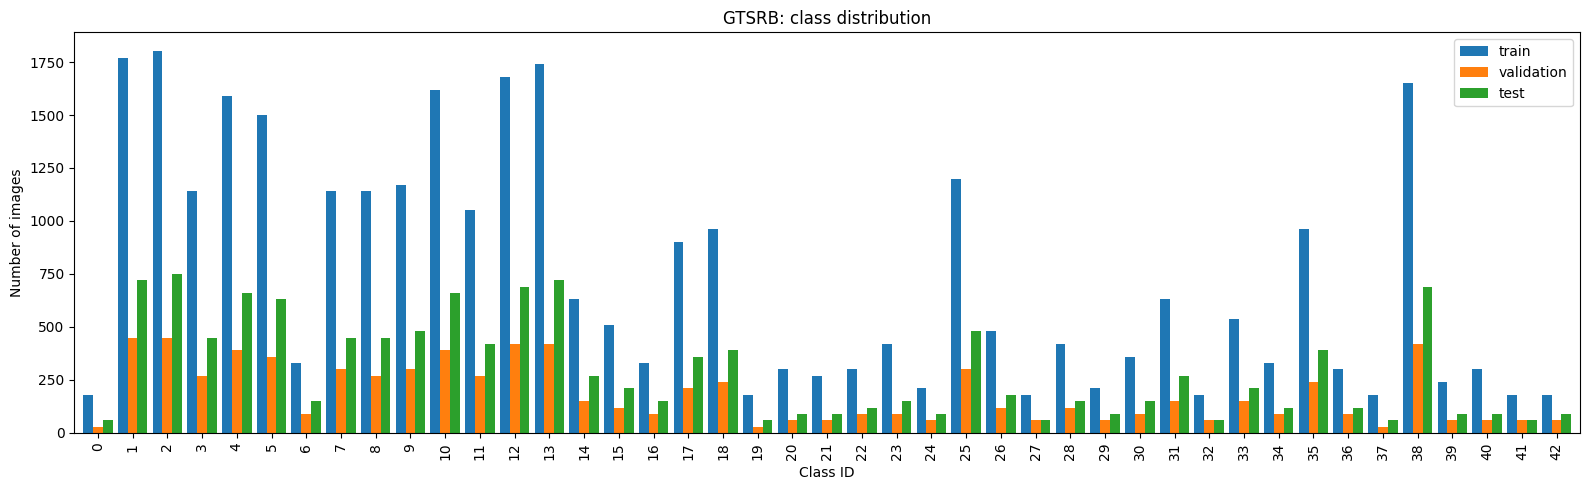

In [7]:
counts = pd.DataFrame({
    name: part.class_id.value_counts().reindex(range(43), fill_value=0)
    for name, part in parts.items()
}).rename_axis("class_id")
counts.to_csv(OUTPUT / "class_distribution.csv")
show_table(counts)

counts.plot.bar(figsize=(16, 5), width=0.85)
plt.title("GTSRB: class distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig(OUTPUT / "class_distribution.png", dpi=150)
plt.show()

## 8. Tên 43 lớp biển báo

Bảng ánh xạ được nhúng trong notebook để có thể dùng độc lập.
Tên Việt là diễn giải biển Đức, không phải khẳng định tương đương quy định biển Việt Nam.

In [8]:
from io import StringIO

CLASS_CSV = """
class_id,name_en,name_vi
0,Speed limit (20 km/h),Giới hạn tốc độ 20 km/h
1,Speed limit (30 km/h),Giới hạn tốc độ 30 km/h
2,Speed limit (50 km/h),Giới hạn tốc độ 50 km/h
3,Speed limit (60 km/h),Giới hạn tốc độ 60 km/h
4,Speed limit (70 km/h),Giới hạn tốc độ 70 km/h
5,Speed limit (80 km/h),Giới hạn tốc độ 80 km/h
6,End of speed limit (80 km/h),Hết giới hạn tốc độ 80 km/h
7,Speed limit (100 km/h),Giới hạn tốc độ 100 km/h
8,Speed limit (120 km/h),Giới hạn tốc độ 120 km/h
9,No passing,Cấm vượt
10,No passing for vehicles over 3.5 metric tons,Cấm vượt đối với xe trên 3.5 tấn
11,Right-of-way at the next intersection,Ưu tiên tại giao lộ tiếp theo
12,Priority road,Đường ưu tiên
13,Yield,Nhường đường
14,Stop,Dừng lại
15,No vehicles,Cấm các loại xe
16,Vehicles over 3.5 metric tons prohibited,Cấm xe trên 3.5 tấn
17,No entry,Cấm đi vào
18,General caution,Cảnh báo nguy hiểm chung
19,Dangerous curve to the left,Đường cong nguy hiểm bên trái
20,Dangerous curve to the right,Đường cong nguy hiểm bên phải
21,Double curve,Đường cong kép
22,Bumpy road,Đường gồ ghề
23,Slippery road,Đường trơn
24,Road narrows on the right,Đường hẹp phía bên phải
25,Road work,Công trường
26,Traffic signals,Tín hiệu đèn giao thông
27,Pedestrians,Người đi bộ
28,Children crossing,Trẻ em qua đường
29,Bicycles crossing,Xe đạp qua đường
30,Beware of ice/snow,Cảnh báo băng tuyết
31,Wild animals crossing,Động vật hoang dã qua đường
32,End of all speed and passing limits,Hết mọi giới hạn tốc độ và cấm vượt
33,Turn right ahead,Bắt buộc rẽ phải phía trước
34,Turn left ahead,Bắt buộc rẽ trái phía trước
35,Ahead only,Chỉ được đi thẳng
36,Go straight or right,Đi thẳng hoặc rẽ phải
37,Go straight or left,Đi thẳng hoặc rẽ trái
38,Keep right,Đi về bên phải
39,Keep left,Đi về bên trái
40,Roundabout mandatory,Bắt buộc đi theo vòng xuyến
41,End of no passing,Hết cấm vượt
42,End of no passing by vehicles over 3.5 metric tons,Hết cấm vượt đối với xe trên 3.5 tấn
"""


class_names = pd.read_csv(StringIO(CLASS_CSV))
assert class_names.class_id.is_unique and set(class_names.class_id) == set(range(43))
class_names.to_csv(OUTPUT / "class_names.csv", index=False, encoding="utf-8-sig")
show_table(class_names)

,class_id,name_en,name_vi
0,0,Speed limit (20 km/h),Giới hạn tốc độ 20 km/h
1,1,Speed limit (30 km/h),Giới hạn tốc độ 30 km/h
2,2,Speed limit (50 km/h),Giới hạn tốc độ 50 km/h
3,3,Speed limit (60 km/h),Giới hạn tốc độ 60 km/h
4,4,Speed limit (70 km/h),Giới hạn tốc độ 70 km/h
5,5,Speed limit (80 km/h),Giới hạn tốc độ 80 km/h
6,6,End of speed limit (80 km/h),Hết giới hạn tốc độ 80 km/h
7,7,Speed limit (100 km/h),Giới hạn tốc độ 100 km/h
8,8,Speed limit (120 km/h),Giới hạn tốc độ 120 km/h
9,9,No passing,Cấm vượt


## 9. Resize và chuyển màu dùng chung

- Đầu vào: ảnh **BGR uint8** đọc bằng OpenCV.
- Resize toàn ảnh về **64×64**, chưa cắt thêm theo ROI; áp dụng giống nhau cho ba phương pháp.
- Thu nhỏ cả hai chiều: `INTER_AREA`; trường hợp khác: `INTER_LINEAR`.
- HSV dành cho lược đồ màu; ảnh xám dành cho HOG. RGB chỉ để hiển thị đúng bằng Matplotlib.
- OpenCV uint8: H từ 0–179, S/V từ 0–255. Histogram dùng miền `[0,180)`, `[0,256)`, `[0,256)`.
- Không dùng CLAHE/lọc nhiễu mặc định. Resize vuông có thể làm biến dạng tỉ lệ; 64×64 là cấu hình khởi đầu.

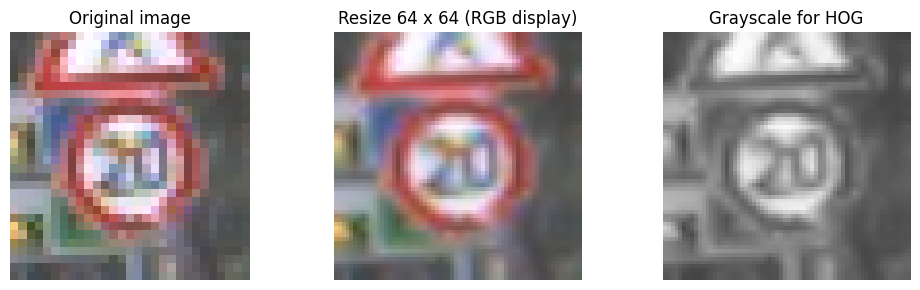

BGR/HSV shape: (64, 64, 3) (64, 64, 3) | Gray shape: (64, 64)
HSV dtype: uint8


In [9]:
def preprocess(image, color="bgr", size=SIZE):
    height, width = image.shape[:2]
    if width >= size[0] and height >= size[1]:
        interpolation = cv2.INTER_AREA
    else:
        interpolation = cv2.INTER_LINEAR
    resized = cv2.resize(image, size, interpolation=interpolation)

    if color == "bgr":
        return resized
    conversions = {
        "rgb": cv2.COLOR_BGR2RGB,
        "hsv": cv2.COLOR_BGR2HSV,
        "gray": cv2.COLOR_BGR2GRAY,
    }
    return cv2.cvtColor(resized, conversions[color])

sample = read_bgr(DATA / parts["train"].iloc[0]["path"])
rgb = preprocess(sample, "rgb")
hsv = preprocess(sample, "hsv")
gray = preprocess(sample, "gray")

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(cv2.cvtColor(sample, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original image")
axes[1].imshow(rgb)
axes[1].set_title("Resize 64 x 64 (RGB display)")
axes[2].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Grayscale for HOG")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT / "preprocessing_example.png", dpi=150)
plt.show()
print("BGR/HSV shape:", rgb.shape, hsv.shape, "| Gray shape:", gray.shape)
print("HSV dtype:", hsv.dtype)

## 10a. Hiển thị và lưu 10 ảnh mẫu train

Lấy ảnh đầu tiên theo tên file của các lớp 0–9 để tái lập, không chọn dựa trên kết quả dự đoán.
Giữ cả ảnh tối/mờ để phản ánh khó khăn thực tế. Đây là minh họa, không đại diện đầy đủ 43 lớp.

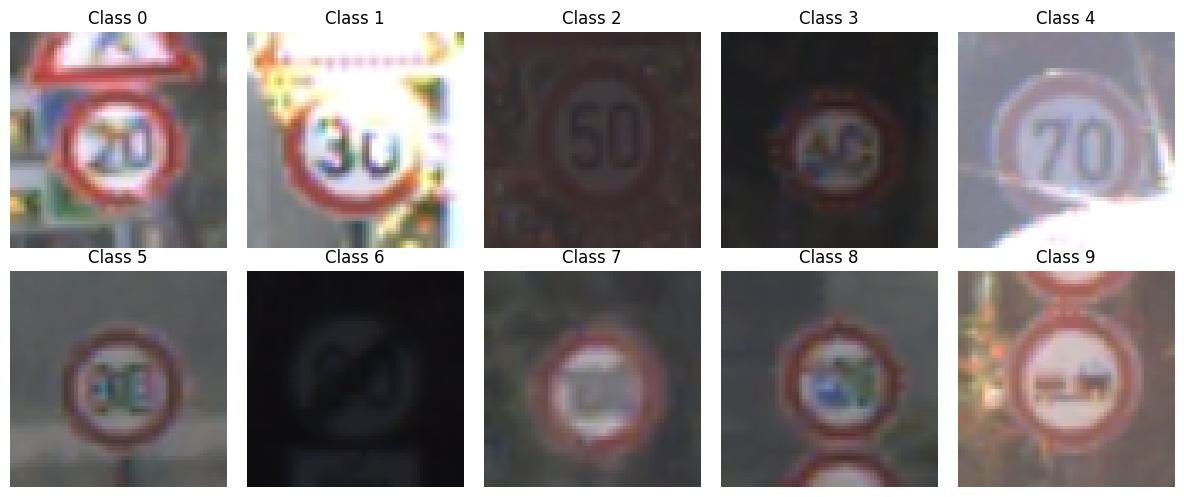

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
sample_records = []
for label, ax in enumerate(axes.flat):
    row = parts["train"].query("class_id == @label").sort_values("path").iloc[0]
    path = DATA / row["path"]
    sample_name = f"class_{label:02d}_{path.name}"
    shutil.copy2(path, SAMPLES / sample_name)
    sample_records.append({"sample": sample_name, "original_path": row["path"],
                           "class_id": label, "split": "train"})
    ax.imshow(preprocess(read_bgr(path), "rgb"))
    ax.set_title(f"Class {label}")
    ax.axis("off")

pd.DataFrame(sample_records).to_csv(SAMPLES / "manifest.csv", index=False)
plt.tight_layout()
plt.savefig(OUTPUT / "training_samples.png", dpi=150)
plt.show()

## 10b. Xem thêm ảnh rõ nét

Các ảnh đầu track thường nhỏ và mờ. Bên dưới chọn thêm ảnh **chỉ từ train** có kích thước lớn và cạnh rõ hơn để dễ quan sát ký hiệu.
Trong mỗi lớp minh họa, lấy 20 ảnh có diện tích lớn nhất rồi chọn ảnh có phương sai Laplacian cao nhất sau khi resize về cùng kích thước.
Đây là tiêu chí gợi ý độ rõ (có thể bị ảnh hưởng bởi nhiễu/nền), không phải nhãn chất lượng chuẩn.

Hiển thị ảnh gốc, không làm nét nhân tạo. Đây là nhóm minh họa có chủ đích; không thay thế nhóm ảnh mờ ở trên, không dùng để chọn dữ liệu kiểm tra hoặc kết luận hiệu năng mô hình.

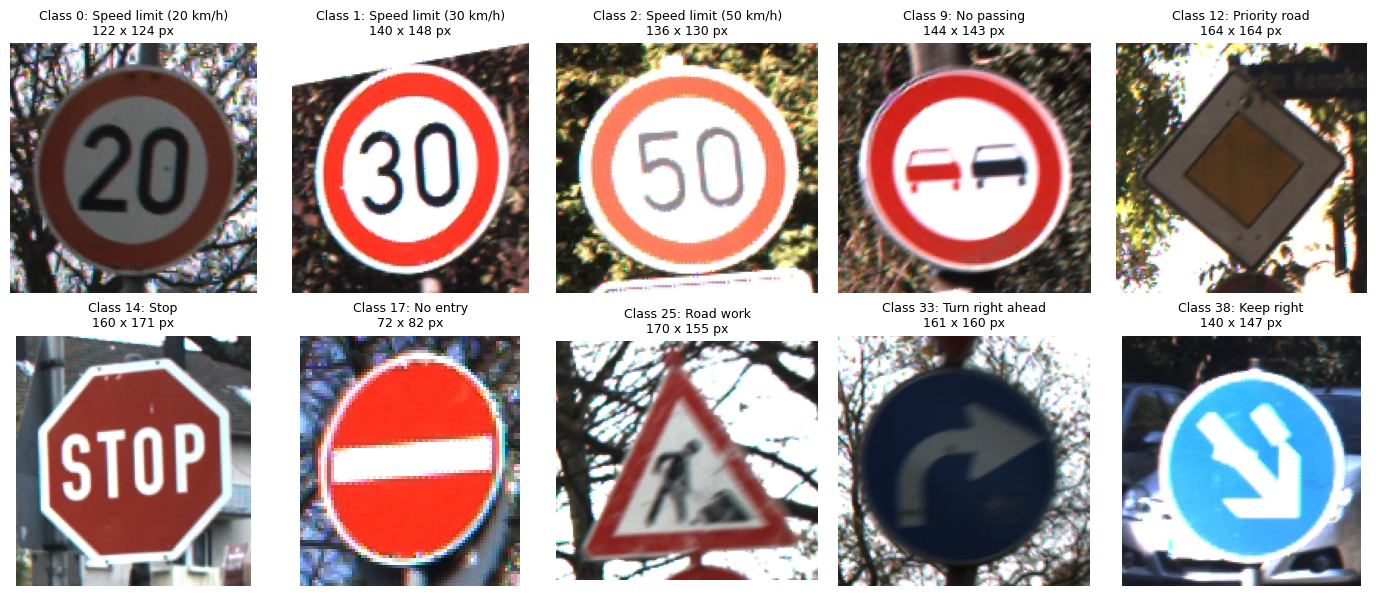

In [11]:
# Chọn 10 lớp có màu sắc và ký hiệu khác nhau, chỉ dùng ảnh train.
labels_to_show = [0, 1, 2, 9, 12, 14, 17, 25, 33, 38]
train_sizes = parts["train"].merge(dimensions_df, on="path")
train_sizes["area"] = train_sizes["width"] * train_sizes["height"]
clear_samples = []

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for label, ax in zip(labels_to_show, axes.flat):
    candidates = train_sizes.query("class_id == @label").sort_values(
        ["area", "path"], ascending=[False, True]
    ).head(20)

    best_score = -1
    for row in candidates.to_dict("records"):
        image = read_bgr(DATA / row["path"])
        gray = preprocess(image, "gray")
        score = cv2.Laplacian(gray, cv2.CV_64F).var()
        if score > best_score:
            best_score = score
            best_image = image
            best_path = row["path"]

    height, width = best_image.shape[:2]
    name = class_names.set_index("class_id").loc[label, "name_en"]
    ax.imshow(cv2.cvtColor(best_image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Class {label}: {name}\n{width} x {height} px", fontsize=9)
    ax.axis("off")
    clear_samples.append({"class_id": label, "path": best_path,
                          "width": width, "height": height,
                          "sharpness_score": float(best_score), "split": "train"})

plt.tight_layout()
plt.savefig(OUTPUT / "clear_training_samples.png", dpi=180)
plt.show()
pd.DataFrame(clear_samples).to_csv(OUTPUT / "clear_training_samples.csv", index=False)

## 11. Kết quả bàn giao

- `splits/train.csv`, `validation.csv`, `test.csv`: dùng chung cho cả ba phương pháp.
- `results/notebook/`: thống kê, nhật ký ảnh lỗi, kích thước, ánh xạ lớp, hình minh họa và `summary.json` chứa seed/hash.
- `samples/`: 10 ảnh mẫu gốc cùng manifest truy nguyên.